
# DATA SCIENCE CAPSTONE PROJECT
## Pengelolaan dan Pemantauan Stok Harian UMKM ROKKUS

### 1. Business Understanding

ROKKUS Mardani Raya merupakan UMKM yang bergerak
di bidang kuliner dengan produk utama berupa roti
kukus dan roti bakar.

Berdasarkan hasil wawancara, proses pencatatan dan
pembaruan data operasional masih dilakukan secara
manual menggunakan Microsoft Excel dan catatan
lainnya.

Permasalahan tersebut menjadi dasar pengembangan
aplikasi pengelolaan dan pemantauan stok harian.

### Tujuan Data Science

1. Memahami karakteristik data persediaan.
2. Menganalisis pergerakan stok barang.
3. Mengidentifikasi pola barang masuk dan keluar.
4. Menghasilkan insight dan rekomendasi bisnis.
5. Menyiapkan data untuk kebutuhan anggota Gen AI.


### Sumber Data

Dataset publik sintetis digunakan sebagai referensi
untuk memahami struktur data inventaris dan
mempelajari proses analisis pergerakan stok.

Dataset ini bukan data operasional asli ROKKUS.

Dataset yang digunakan:
- warehouses.csv
- stock_items.csv
- stock_movements.csv

Sumber dataset:
Inventory Stock Movements and Reorder Point Thresholds
Database Sample.

Dataset sintetis khusus ROKKUS akan disiapkan secara
terpisah untuk simulasi kebutuhan proyek.


In [1]:

# Import library yang dibutuhkan

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Library berhasil diimpor!")


Library berhasil diimpor!


In [2]:

# Mengambil dataset publik dari Database Sample

base_url = "https://database-sample-website.s3.eu-north-1.amazonaws.com/datasets/inventory-stock-movements-and-reorder-point-thresholds/v1/csv/"

warehouses = pd.read_csv(base_url + "warehouses.csv")

stock_items = pd.read_csv(base_url + "stock_items.csv")

stock_movements = pd.read_csv(base_url + "stock_movements.csv")

print("Semua dataset berhasil dimuat!")


Semua dataset berhasil dimuat!


In [3]:

print("JUMLAH DATASET")

print("Warehouses:", warehouses.shape)
print("Stock Items:", stock_items.shape)
print("Stock Movements:", stock_movements.shape)


JUMLAH DATASET
Warehouses: (4, 5)
Stock Items: (80, 9)
Stock Movements: (543, 7)


In [4]:

# Menampilkan 5 data pertama

print("DATA BARANG")
display(stock_items.head())

print("DATA TRANSAKSI")
display(stock_movements.head())


DATA BARANG


,id,warehouse_id,sku,product_name,opening_on_hand,counted_at,reorder_point,reorder_qty,lead_time_days
0,1,1,SKU-428373,Bluetooth Speaker,236,2024-08-31 13:52:30,94,120,5
1,2,3,SKU-602941,Umbrella,158,2024-08-31 11:29:36,161,228,21
2,3,1,SKU-350926,Yoga Mat,178,2024-08-31 06:31:22,192,264,3
3,4,4,SKU-362300,Desk Lamp,481,2024-08-31 10:23:21,132,245,18
4,5,1,SKU-944979,Pillow,297,2024-08-31 09:40:37,176,156,6


DATA TRANSAKSI


,id,stock_item_id,movement_type,units_in,units_out,quantity_change,moved_at
0,1,59,adjustment,NaN,2.0,-2,2024-09-01 08:57:34
1,2,23,adjustment,NaN,1.0,-1,2024-09-01 10:48:54
2,3,15,transfer_out,NaN,7.0,-7,2024-09-01 04:59:26
3,4,10,sale,NaN,1.0,-1,2024-09-01 16:04:59
4,5,71,sale,NaN,11.0,-11,2024-09-01 04:50:23


In [5]:

print("STRUKTUR DATA BARANG")
stock_items.info()

print("\nSTRUKTUR DATA TRANSAKSI")
stock_movements.info()


STRUKTUR DATA BARANG
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 80 entries, 0 to 79
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   id               80 non-null     int64 
 1   warehouse_id     80 non-null     int64 
 2   sku              80 non-null     object
 3   product_name     80 non-null     object
 4   opening_on_hand  80 non-null     int64 
 5   counted_at       80 non-null     object
 6   reorder_point    80 non-null     int64 
 7   reorder_qty      80 non-null     int64 
 8   lead_time_days   80 non-null     int64 
dtypes: int64(6), object(3)
memory usage: 5.8+ KB

STRUKTUR DATA TRANSAKSI
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 543 entries, 0 to 542
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   id               543 non-null    int64  
 1   stock_item_id    543 non-null    int64  
 2   movement_type 

In [6]:

print("STATISTIK DATA BARANG")
display(stock_items.describe())

print("STATISTIK TRANSAKSI")
display(stock_movements.describe())


STATISTIK DATA BARANG


,id,warehouse_id,opening_on_hand,reorder_point,reorder_qty,lead_time_days
count,80.0000,80.000000,80.000000,80.000000,80.000000,80.0000
mean,40.5000,2.500000,311.750000,152.825000,239.612500,8.8875
std,23.2379,1.102357,102.482292,44.891931,83.320563,6.0525
min,1.0000,1.000000,154.000000,81.000000,102.000000,2.0000
25%,20.7500,2.000000,217.500000,107.750000,173.250000,3.0000
50%,40.5000,2.000000,312.500000,152.500000,223.000000,8.0000
75%,60.2500,3.250000,402.750000,192.250000,307.000000,14.0000
max,80.0000,4.000000,495.000000,218.000000,389.000000,21.0000


STATISTIK TRANSAKSI


,id,stock_item_id,units_in,units_out,quantity_change
count,543.000000,543.000000,58.000000,485.000000,543.000000
mean,272.000000,43.480663,241.637931,4.855670,21.473297
std,156.894869,23.593011,86.793705,3.399653,81.301627
min,1.000000,1.000000,87.000000,1.000000,-12.000000
25%,136.500000,23.000000,172.000000,2.000000,-7.000000
50%,272.000000,45.000000,223.000000,4.000000,-3.000000
75%,407.500000,65.000000,309.750000,8.000000,-1.000000
max,543.000000,80.000000,390.000000,12.000000,390.000000


In [7]:

print("MISSING VALUE DATA BARANG")
display(stock_items.isnull().sum())

print("MISSING VALUE TRANSAKSI")
display(stock_movements.isnull().sum())


MISSING VALUE DATA BARANG


,0
id,0
warehouse_id,0
sku,0
product_name,0
opening_on_hand,0
counted_at,0
reorder_point,0
reorder_qty,0
lead_time_days,0


MISSING VALUE TRANSAKSI


,0
id,0
stock_item_id,0
movement_type,0
units_in,485
units_out,58
quantity_change,0
moved_at,0


In [8]:

print("DUPLIKAT DATA BARANG:")
print(stock_items.duplicated().sum())

print("DUPLIKAT DATA TRANSAKSI:")
print(stock_movements.duplicated().sum())


DUPLIKAT DATA BARANG:
0
DUPLIKAT DATA TRANSAKSI:
0


In [9]:
print("Kolom stock_items:")
print(stock_items.columns.tolist())

print("\nKolom stock_movements:")
print(stock_movements.columns.tolist())

print("\nKolom warehouses:")
print(warehouses.columns.tolist())

Kolom stock_items:
['id', 'warehouse_id', 'sku', 'product_name', 'opening_on_hand', 'counted_at', 'reorder_point', 'reorder_qty', 'lead_time_days']

Kolom stock_movements:
['id', 'stock_item_id', 'movement_type', 'units_in', 'units_out', 'quantity_change', 'moved_at']

Kolom warehouses:
['id', 'code', 'city', 'dock_doors', 'opened_on']


In [10]:
display(stock_items.head(10))
display(stock_movements.head(10))
display(warehouses.head(10))

,id,warehouse_id,sku,product_name,opening_on_hand,counted_at,reorder_point,reorder_qty,lead_time_days
0,1,1,SKU-428373,Bluetooth Speaker,236,2024-08-31 13:52:30,94,120,5
1,2,3,SKU-602941,Umbrella,158,2024-08-31 11:29:36,161,228,21
2,3,1,SKU-350926,Yoga Mat,178,2024-08-31 06:31:22,192,264,3
3,4,4,SKU-362300,Desk Lamp,481,2024-08-31 10:23:21,132,245,18
4,5,1,SKU-944979,Pillow,297,2024-08-31 09:40:37,176,156,6
5,6,1,SKU-668572,Hand Cream,213,2024-08-31 09:01:49,210,185,5
6,7,3,SKU-492101,Pillow,160,2024-08-31 16:52:49,216,271,2
7,8,3,SKU-493138,Puzzle 1000pc,253,2024-08-31 10:04:34,142,389,19
8,9,4,SKU-223250,Lunch Box,239,2024-08-31 11:27:20,187,306,5
9,10,3,SKU-728856,Notebook A5,193,2024-08-31 15:59:37,159,260,15


,id,stock_item_id,movement_type,units_in,units_out,quantity_change,moved_at
0,1,59,adjustment,NaN,2.0,-2,2024-09-01 08:57:34
1,2,23,adjustment,NaN,1.0,-1,2024-09-01 10:48:54
2,3,15,transfer_out,NaN,7.0,-7,2024-09-01 04:59:26
3,4,10,sale,NaN,1.0,-1,2024-09-01 16:04:59
4,5,71,sale,NaN,11.0,-11,2024-09-01 04:50:23
5,6,26,sale,NaN,5.0,-5,2024-09-01 21:30:50
6,7,34,transfer_out,NaN,7.0,-7,2024-09-01 08:51:34
7,8,75,receipt,359.0,NaN,359,2024-09-01 15:28:18
8,9,47,adjustment,NaN,2.0,-2,2024-09-01 23:44:53
9,10,8,sale,NaN,4.0,-4,2024-09-01 12:11:40


,id,code,city,dock_doors,opened_on
0,1,WH-14,Fort Meggiechester,20,2020-04-27
1,2,WH-79,South Bernieceview,7,2015-06-17
2,3,WH-34,Port Lisatown,8,2015-03-01
3,4,WH-54,National City,11,2022-03-07


In [11]:
print("Jumlah data stock_items:", len(stock_items))
print("Jumlah data stock_movements:", len(stock_movements))
print("Jumlah data warehouses:", len(warehouses))

Jumlah data stock_items: 80
Jumlah data stock_movements: 543
Jumlah data warehouses: 4


In [12]:
print("Missing Values Stock Items")
print(stock_items.isnull().sum())

print("\nMissing Values Stock Movements")
print(stock_movements.isnull().sum())

print("\nMissing Values Warehouses")
print(warehouses.isnull().sum())

Missing Values Stock Items
id                 0
warehouse_id       0
sku                0
product_name       0
opening_on_hand    0
counted_at         0
reorder_point      0
reorder_qty        0
lead_time_days     0
dtype: int64

Missing Values Stock Movements
id                   0
stock_item_id        0
movement_type        0
units_in           485
units_out           58
quantity_change      0
moved_at             0
dtype: int64

Missing Values Warehouses
id            0
code          0
city          0
dock_doors    0
opened_on     0
dtype: int64


In [13]:
print("Duplikat Stock Items:", stock_items.duplicated().sum())

print("Duplikat Stock Movements:", stock_movements.duplicated().sum())

print("Duplikat Warehouses:", warehouses.duplicated().sum())

Duplikat Stock Items: 0
Duplikat Stock Movements: 0
Duplikat Warehouses: 0


In [14]:
print(stock_movements["movement_type"].value_counts())

movement_type
sale            366
transfer_out     63
receipt          58
adjustment       56
Name: count, dtype: int64


In [15]:
print("Tanggal transaksi paling awal:")
print(stock_movements["moved_at"].min())

print("\nTanggal transaksi paling akhir:")
print(stock_movements["moved_at"].max())

Tanggal transaksi paling awal:
2024-08-31 11:49:31

Tanggal transaksi paling akhir:
2024-09-17 05:44:40


In [16]:
# Memeriksa missing values berdasarkan jenis transaksi

print(
    stock_movements.groupby("movement_type")[
        ["units_in", "units_out"]
    ].apply(lambda x: x.isnull().sum())
)

               units_in  units_out
movement_type                     
adjustment           56          0
receipt               0         58
sale                366          0
transfer_out         63          0


In [17]:
# Melihat contoh transaksi berdasarkan jenis pergerakan

for jenis in stock_movements["movement_type"].unique():
    print("\nJenis transaksi:", jenis)

    display(
        stock_movements[
            stock_movements["movement_type"] == jenis
        ][["movement_type", "units_in", "units_out", "quantity_change"]]
        .head(5)
    )


Jenis transaksi: adjustment


,movement_type,units_in,units_out,quantity_change
0,adjustment,NaN,2.0,-2
1,adjustment,NaN,1.0,-1
8,adjustment,NaN,2.0,-2
38,adjustment,NaN,5.0,-5
43,adjustment,NaN,11.0,-11



Jenis transaksi: transfer_out


,movement_type,units_in,units_out,quantity_change
2,transfer_out,NaN,7.0,-7
6,transfer_out,NaN,7.0,-7
23,transfer_out,NaN,3.0,-3
24,transfer_out,NaN,1.0,-1
26,transfer_out,NaN,8.0,-8



Jenis transaksi: sale


,movement_type,units_in,units_out,quantity_change
3,sale,NaN,1.0,-1
4,sale,NaN,11.0,-11
5,sale,NaN,5.0,-5
9,sale,NaN,4.0,-4
10,sale,NaN,3.0,-3



Jenis transaksi: receipt


,movement_type,units_in,units_out,quantity_change
7,receipt,359.0,NaN,359
16,receipt,369.0,NaN,369
17,receipt,196.0,NaN,196
22,receipt,169.0,NaN,169
25,receipt,384.0,NaN,384


In [18]:
# Memeriksa kesesuaian perubahan stok

stock_movements["calculated_change"] = (
    stock_movements["units_in"].fillna(0)
    - stock_movements["units_out"].fillna(0)
)

stock_movements["is_consistent"] = (
    stock_movements["quantity_change"]
    == stock_movements["calculated_change"]
)

print("Jumlah data konsisten:")
print(stock_movements["is_consistent"].sum())

print("\nJumlah data tidak konsisten:")
print((~stock_movements["is_consistent"]).sum())

Jumlah data konsisten:
543

Jumlah data tidak konsisten:
0


In [19]:
# Melihat transaksi yang tidak konsisten

inconsistent_data = stock_movements[
    stock_movements["is_consistent"] == False
]

display(inconsistent_data.head(10))

,id,stock_item_id,movement_type,units_in,units_out,quantity_change,moved_at,calculated_change,is_consistent


### Hasil Data Quality Assessment

Berdasarkan pemeriksaan kualitas dataset, diperoleh hasil sebagai berikut:

1. Dataset `stock_items` memiliki 80 baris data dan tidak ditemukan missing values.
2. Dataset `stock_movements` memiliki 543 baris data. Missing values ditemukan pada kolom `units_in` sebanyak 485 nilai dan `units_out` sebanyak 58 nilai. Nilai kosong tersebut berkaitan dengan jenis transaksi yang dilakukan.
3. Dataset `warehouses` memiliki 4 baris data dan tidak ditemukan missing values.
4. Pemeriksaan konsistensi menunjukkan bahwa seluruh 543 transaksi memiliki nilai `quantity_change` yang sesuai dengan hasil perhitungan `units_in - units_out`.
5. Belum ditemukan ketidaksesuaian perhitungan perubahan stok.

Dengan demikian, dataset memiliki konsistensi perhitungan perubahan stok yang baik. Missing values pada kolom transaksi akan dipertahankan karena berkaitan dengan jenis pergerakan stok.

In [20]:
# Memeriksa duplikasi berdasarkan ID

print("Duplikat ID stock_items:",
      stock_items["id"].duplicated().sum())

print("Duplikat ID stock_movements:",
      stock_movements["id"].duplicated().sum())

print("Duplikat ID warehouses:",
      warehouses["id"].duplicated().sum())

Duplikat ID stock_items: 0
Duplikat ID stock_movements: 0
Duplikat ID warehouses: 0


In [21]:
# Memeriksa apakah relasi antar tabel valid

print("Stock item tanpa warehouse:")
print(
    (~stock_items["warehouse_id"].isin(warehouses["id"])).sum()
)

print("\nMovement tanpa stock item:")
print(
    (~stock_movements["stock_item_id"].isin(stock_items["id"])).sum()
)

Stock item tanpa warehouse:
0

Movement tanpa stock item:
0


### Pemeriksaan Duplikasi dan Relasi Data

Berdasarkan pemeriksaan yang dilakukan, diperoleh hasil:

1. Tidak ditemukan duplikasi ID pada dataset `stock_items`, `stock_movements`, dan `warehouses`.
2. Tidak ditemukan data barang yang memiliki `warehouse_id` tanpa pasangan pada tabel `warehouses`.
3. Tidak ditemukan data pergerakan stok yang memiliki `stock_item_id` tanpa pasangan pada tabel `stock_items`.

Hasil tersebut menunjukkan bahwa ID pada ketiga dataset tidak mengalami duplikasi dan hubungan antar tabel dapat terhubung dengan baik berdasarkan kolom ID yang diperiksa.

In [22]:
# Menggabungkan stock_movements dengan stock_items

movement_data = stock_movements.merge(
    stock_items[["id", "product_name", "sku", "reorder_point"]],
    left_on="stock_item_id",
    right_on="id",
    how="left",
    suffixes=("_movement", "_item")
)

display(movement_data.head())

,id_movement,stock_item_id,movement_type,units_in,units_out,quantity_change,moved_at,calculated_change,is_consistent,id_item,product_name,sku,reorder_point
0,1,59,adjustment,NaN,2.0,-2,2024-09-01 08:57:34,-2.0,True,59,Pillow,SKU-643269,107
1,2,23,adjustment,NaN,1.0,-1,2024-09-01 10:48:54,-1.0,True,23,Desk Lamp,SKU-886524,210
2,3,15,transfer_out,NaN,7.0,-7,2024-09-01 04:59:26,-7.0,True,15,Bath Towel,SKU-793887,92
3,4,10,sale,NaN,1.0,-1,2024-09-01 16:04:59,-1.0,True,10,Notebook A5,SKU-728856,159
4,5,71,sale,NaN,11.0,-11,2024-09-01 04:50:23,-11.0,True,71,Shower Gel,SKU-704144,190


In [23]:
# Ringkasan jumlah stok masuk dan keluar

print("Total stok masuk:")
print(movement_data["units_in"].sum())

print("\nTotal stok keluar:")
print(movement_data["units_out"].sum())

print("\nTotal perubahan stok:")
print(movement_data["quantity_change"].sum())

Total stok masuk:
14015.0

Total stok keluar:
2355.0

Total perubahan stok:
11660


In [24]:
# Menghitung jumlah transaksi berdasarkan jenisnya

transaction_count = movement_data["movement_type"].value_counts()

display(transaction_count)

,count
movement_type,
sale,366
transfer_out,63
receipt,58
adjustment,56


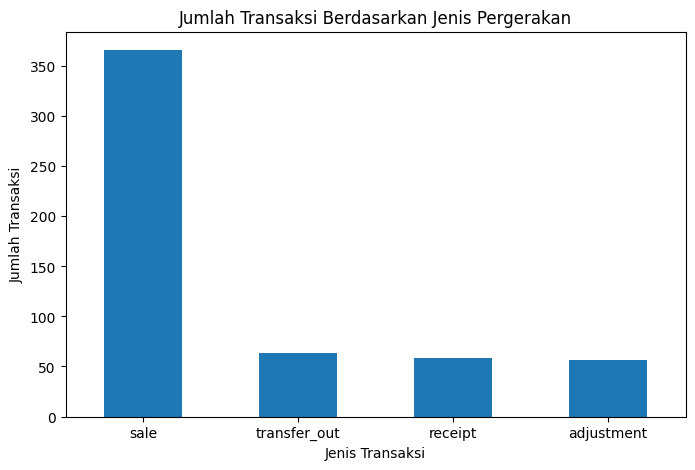

In [25]:
# Visualisasi jumlah transaksi

transaction_count.plot(
    kind="bar",
    figsize=(8, 5),
    title="Jumlah Transaksi Berdasarkan Jenis Pergerakan"
)

plt.xlabel("Jenis Transaksi")
plt.ylabel("Jumlah Transaksi")
plt.xticks(rotation=0)
plt.show()

In [26]:
# Menghitung total pergerakan berdasarkan produk

product_movement = (
    movement_data.groupby("product_name")["quantity_change"]
    .sum()
    .sort_values(ascending=False)
)

display(product_movement.head(10))

,quantity_change
product_name,
Phone Charging Cable,1824
Extension Lead,1261
Coffee Grinder,1176
Yoga Mat,1050
LED Bulb Pack,894
Bath Towel,731
Sunglasses,647
Umbrella,589
Notebook A5,529


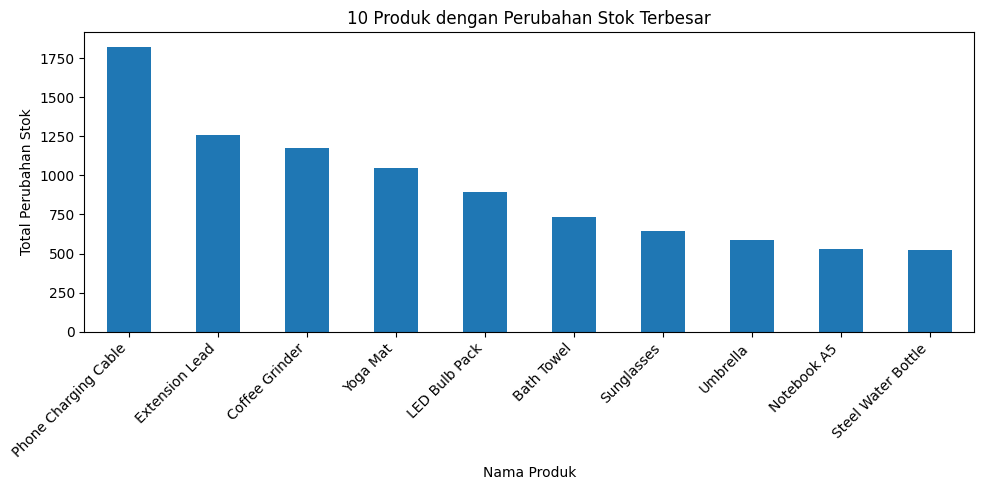

In [27]:
# Visualisasi 10 produk dengan perubahan stok terbesar

product_movement.head(10).plot(
    kind="bar",
    figsize=(10, 5),
    title="10 Produk dengan Perubahan Stok Terbesar"
)

plt.xlabel("Nama Produk")
plt.ylabel("Total Perubahan Stok")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### Hasil Exploratory Data Analysis (EDA)

**1. Analisis Jenis Transaksi**

Berdasarkan hasil eksplorasi terhadap 543 transaksi, jenis transaksi yang paling dominan adalah sale sebanyak 366 transaksi atau sekitar 67,4%. Selanjutnya terdapat transfer_out sebanyak 63 transaksi, receipt sebanyak 58 transaksi, dan adjustment sebanyak 56 transaksi.

Hasil ini menunjukkan bahwa aktivitas penjualan merupakan jenis pergerakan stok yang paling sering tercatat dalam dataset.

**2. Analisis Perubahan Stok Berdasarkan Produk**

Berdasarkan perhitungan total perubahan stok bersih, Phone Charging Cable memiliki nilai tertinggi sebesar 1.824 unit, diikuti Extension Lead sebesar 1.261 unit dan Coffee Grinder sebesar 1.176 unit.

Hasil ini menunjukkan bahwa ketiga produk tersebut memiliki akumulasi perubahan stok bersih terbesar selama periode pengamatan.

**Catatan:** Dataset yang dianalisis merupakan dataset publik dan bukan data operasional asli UMKM ROKKUS. Oleh karena itu, hasil analisis digunakan sebagai referensi untuk memahami pola pergerakan stok dan mengembangkan pendekatan analisis pada proyek.

In [28]:
# Mengambil transaksi penjualan saja

sales_data = movement_data[
    movement_data["movement_type"] == "sale"
]

# Menghitung total penjualan setiap produk

top_selling_products = (
    sales_data.groupby("product_name")["units_out"]
    .sum()
    .sort_values(ascending=False)
)

display(top_selling_products.head(10))

,units_out
product_name,
Yoga Mat,138.0
Pillow,125.0
Lunch Box,117.0
Desk Lamp,108.0
Extension Lead,102.0
Puzzle 1000pc,97.0
Sunglasses,96.0
Phone Charging Cable,96.0
Notebook A5,92.0


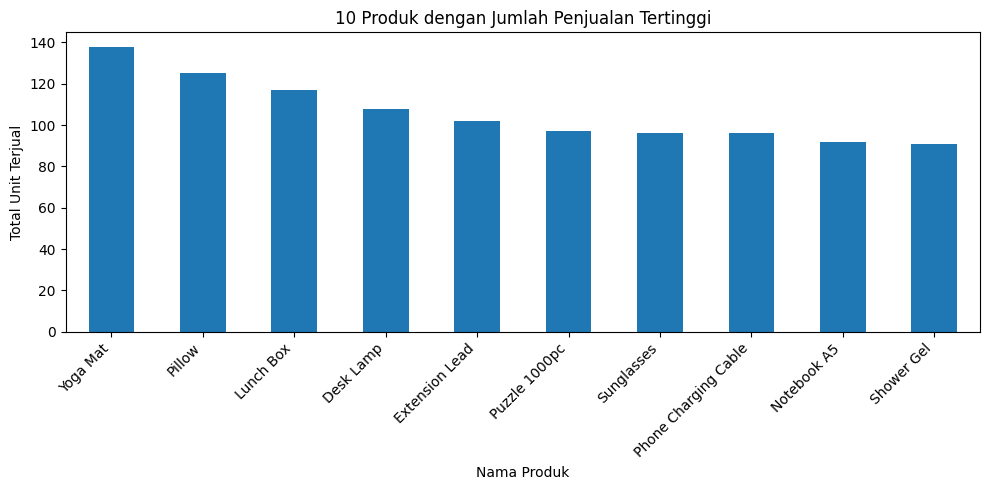

In [29]:
top_selling_products.head(10).plot(
    kind="bar",
    figsize=(10, 5),
    title="10 Produk dengan Jumlah Penjualan Tertinggi"
)

plt.xlabel("Nama Produk")
plt.ylabel("Total Unit Terjual")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### Analisis Produk dengan Jumlah Penjualan Tertinggi

Analisis dilakukan dengan memfilter transaksi yang memiliki jenis pergerakan `sale`, kemudian menjumlahkan nilai `units_out` berdasarkan nama produk.

Berdasarkan hasil analisis, Yoga Mat menempati peringkat pertama dengan jumlah penjualan sebanyak 138 unit. Selanjutnya, Pillow berada di posisi kedua dengan 125 unit, dan Lunch Box berada di posisi ketiga dengan 117 unit.

Hasil ini menunjukkan bahwa Yoga Mat merupakan produk dengan jumlah unit terjual tertinggi di antara produk yang dianalisis.

Temuan ini dapat menjadi referensi untuk memahami bagaimana data transaksi penjualan dapat digunakan dalam pemantauan persediaan barang.

**Catatan:** Hasil analisis berasal dari dataset publik, bukan data transaksi asli UMKM ROKKUS.

In [30]:
# Menghitung status persediaan setiap produk

stock_items["stock_status"] = np.where(
    stock_items["opening_on_hand"] <= stock_items["reorder_point"],
    "Low Stock",
    "Safe Stock"
)

display(
    stock_items[
        ["product_name", "opening_on_hand", "reorder_point", "stock_status"]
    ].head(10)
)

,product_name,opening_on_hand,reorder_point,stock_status
0,Bluetooth Speaker,236,94,Safe Stock
1,Umbrella,158,161,Low Stock
2,Yoga Mat,178,192,Low Stock
3,Desk Lamp,481,132,Safe Stock
4,Pillow,297,176,Safe Stock
5,Hand Cream,213,210,Safe Stock
6,Pillow,160,216,Low Stock
7,Puzzle 1000pc,253,142,Safe Stock
8,Lunch Box,239,187,Safe Stock
9,Notebook A5,193,159,Safe Stock


In [31]:
# Menghitung jumlah produk berdasarkan status stok

stock_status_count = stock_items["stock_status"].value_counts()

display(stock_status_count)

,count
stock_status,
Safe Stock,69
Low Stock,11


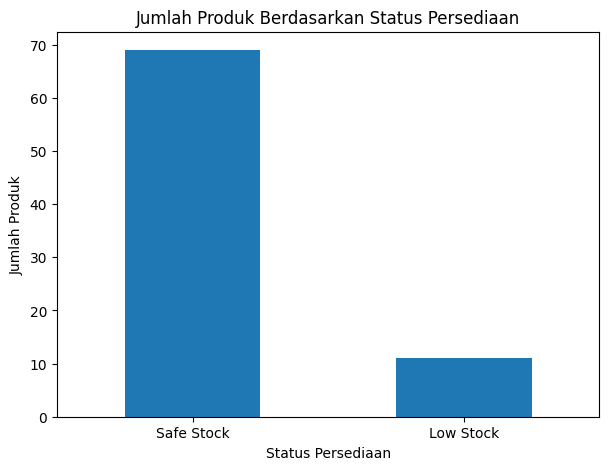

In [32]:
stock_status_count.plot(
    kind="bar",
    figsize=(7, 5),
    title="Jumlah Produk Berdasarkan Status Persediaan"
)

plt.xlabel("Status Persediaan")
plt.ylabel("Jumlah Produk")
plt.xticks(rotation=0)
plt.show()

### Analisis Status Persediaan Berdasarkan Reorder Point

Analisis dilakukan dengan membandingkan nilai `opening_on_hand` dengan `reorder_point` pada setiap produk.

Berdasarkan hasil analisis terhadap 80 produk, terdapat 69 produk dengan status Safe Stock dan 11 produk dengan status Low Stock.

Produk dikategorikan sebagai Low Stock apabila jumlah stok awal lebih kecil atau sama dengan nilai reorder point. Sementara itu, produk dengan jumlah stok awal di atas reorder point dikategorikan sebagai Safe Stock.

Hasil tersebut menunjukkan bahwa 13,75% produk berada pada kondisi yang perlu diperhatikan karena stoknya telah mencapai atau berada di bawah batas pemesanan ulang.

Temuan ini dapat menjadi referensi dalam pengembangan fitur pemantauan persediaan dan notifikasi stok rendah pada aplikasi pengelolaan stok UMKM ROKKUS.

**Catatan:** Klasifikasi ini menggunakan data publik dan stok awal, bukan kondisi stok terkini UMKM ROKKUS.

In [33]:
# Menampilkan seluruh produk dengan status Low Stock

low_stock_products = stock_items[
    stock_items["stock_status"] == "Low Stock"
]

display(
    low_stock_products[
        [
            "product_name",
            "opening_on_hand",
            "reorder_point",
            "reorder_qty"
        ]
    ].sort_values(
        by="opening_on_hand",
        ascending=True
    )
)

,product_name,opening_on_hand,reorder_point,reorder_qty
40,LED Bulb Pack,155,180,148
1,Umbrella,158,161,228
6,Pillow,160,216,271
13,Pillow,162,188,147
34,Yoga Mat,167,213,194
2,Yoga Mat,178,192,264
64,Yoga Mat,181,193,368
70,Shower Gel,182,190,113
52,Lunch Box,187,216,357
42,Kitchen Scale,191,215,349


In [34]:
# Menghitung selisih stok terhadap reorder point

low_stock_products = low_stock_products.copy()

low_stock_products["stock_difference"] = (
    low_stock_products["opening_on_hand"]
    - low_stock_products["reorder_point"]
)

display(
    low_stock_products[
        [
            "product_name",
            "opening_on_hand",
            "reorder_point",
            "stock_difference"
        ]
    ]
)

,product_name,opening_on_hand,reorder_point,stock_difference
1,Umbrella,158,161,-3
2,Yoga Mat,178,192,-14
6,Pillow,160,216,-56
13,Pillow,162,188,-26
34,Yoga Mat,167,213,-46
40,LED Bulb Pack,155,180,-25
42,Kitchen Scale,191,215,-24
50,Coffee Grinder,197,201,-4
52,Lunch Box,187,216,-29
64,Yoga Mat,181,193,-12


### Analisis Produk dengan Status Low Stock

Berdasarkan hasil analisis, ditemukan 11 item persediaan dengan status Low Stock dari total 80 item.

Setiap item memiliki nilai stok awal yang lebih kecil dibandingkan reorder point. Selisih antara stok awal dan reorder point menunjukkan tingkat kekurangan persediaan terhadap batas pemesanan ulang.

Item Pillow dengan stok awal 160 unit memiliki selisih terbesar, yaitu 56 unit di bawah reorder point. Selain itu, terdapat tiga item Yoga Mat yang termasuk dalam kategori Low Stock.

Temuan ini menunjukkan bahwa perbandingan antara jumlah stok dan reorder point dapat digunakan untuk mengidentifikasi item persediaan yang membutuhkan perhatian lebih.

Hasil analisis ini dapat menjadi referensi dalam pengembangan fitur peringatan stok rendah pada aplikasi pengelolaan persediaan.

**Catatan:** Analisis menggunakan dataset publik, bukan data persediaan aktual UMKM ROKKUS.

In [36]:
# Menghitung total perubahan stok per item

total_movement = (
    movement_data.groupby("stock_item_id")["quantity_change"]
    .sum()
    .reset_index()
)

# Menggabungkan dengan data stok awal

stock_analysis = stock_items.merge(
    total_movement,
    left_on="id",
    right_on="stock_item_id",
    how="left"
)

# Menghitung estimasi stok akhir

stock_analysis["estimated_ending_stock"] = (
    stock_analysis["opening_on_hand"]
    + stock_analysis["quantity_change"]
)

display(
    stock_analysis[
        [
            "product_name",
            "opening_on_hand",
            "quantity_change",
            "estimated_ending_stock",
            "reorder_point"
        ]
    ].head(10)
)

,product_name,opening_on_hand,quantity_change,estimated_ending_stock,reorder_point
0,Bluetooth Speaker,236,-35,201,94
1,Umbrella,158,284,442,161
2,Yoga Mat,178,138,316,192
3,Desk Lamp,481,-29,452,132
4,Pillow,297,90,387,176
5,Hand Cream,213,-42,171,210
6,Pillow,160,-24,136,216
7,Puzzle 1000pc,253,-47,206,142
8,Lunch Box,239,-16,223,187
9,Notebook A5,193,203,396,159


In [37]:
# Memeriksa apakah ada estimasi stok akhir negatif

print(
    "Jumlah item dengan estimasi stok negatif:",
    (stock_analysis["estimated_ending_stock"] < 0).sum()
)

Jumlah item dengan estimasi stok negatif: 0


In [38]:
# Mengklasifikasikan status berdasarkan estimasi stok akhir

stock_analysis["ending_stock_status"] = np.where(
    stock_analysis["estimated_ending_stock"]
    <= stock_analysis["reorder_point"],
    "Low Stock",
    "Safe Stock"
)

display(
    stock_analysis[
        [
            "product_name",
            "estimated_ending_stock",
            "reorder_point",
            "ending_stock_status"
        ]
    ].head(15)
)

,product_name,estimated_ending_stock,reorder_point,ending_stock_status
0,Bluetooth Speaker,201,94,Safe Stock
1,Umbrella,442,161,Safe Stock
2,Yoga Mat,316,192,Safe Stock
3,Desk Lamp,452,132,Safe Stock
4,Pillow,387,176,Safe Stock
5,Hand Cream,171,210,Low Stock
6,Pillow,136,216,Low Stock
7,Puzzle 1000pc,206,142,Safe Stock
8,Lunch Box,223,187,Safe Stock
9,Notebook A5,396,159,Safe Stock


In [39]:
ending_status_count = (
    stock_analysis["ending_stock_status"].value_counts()
)

display(ending_status_count)

,count
ending_stock_status,
Safe Stock,73
Low Stock,7


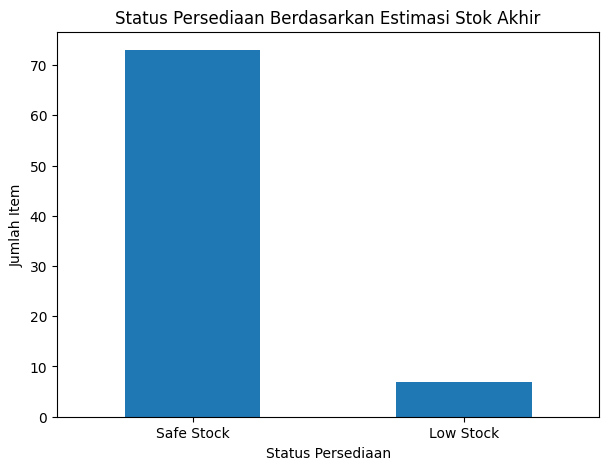

In [40]:
ending_status_count.plot(
    kind="bar",
    figsize=(7, 5),
    title="Status Persediaan Berdasarkan Estimasi Stok Akhir"
)

plt.xlabel("Status Persediaan")
plt.ylabel("Jumlah Item")
plt.xticks(rotation=0)
plt.show()

### Perbandingan Status Stok Awal dan Estimasi Stok Akhir

Berdasarkan hasil klasifikasi persediaan, terdapat perubahan jumlah item berdasarkan status stok awal dan estimasi stok akhir.

Pada kondisi stok awal, sebanyak 69 item termasuk kategori Safe Stock dan 11 item termasuk kategori Low Stock.

Setelah memperhitungkan seluruh perubahan stok dari transaksi yang tersedia, diperoleh 73 item dengan kategori Safe Stock dan 7 item dengan kategori Low Stock.

Hasil ini menunjukkan adanya penurunan jumlah item dengan status Low Stock sebanyak 4 item. Perubahan tersebut menggambarkan bagaimana transaksi barang masuk dan keluar dapat memengaruhi kondisi persediaan.

Analisis ini dapat menjadi referensi untuk pengembangan fitur pemantauan stok dan notifikasi persediaan rendah pada aplikasi UMKM ROKKUS.

**Catatan:** Hasil merupakan simulasi menggunakan dataset publik dan belum menggambarkan kondisi aktual stok UMKM ROKKUS.

In [41]:
# Menampilkan item yang masih Low Stock

remaining_low_stock = stock_analysis[
    stock_analysis["ending_stock_status"] == "Low Stock"
].copy()

remaining_low_stock["stock_difference"] = (
    remaining_low_stock["estimated_ending_stock"]
    - remaining_low_stock["reorder_point"]
)

display(
    remaining_low_stock[
        [
            "product_name",
            "opening_on_hand",
            "quantity_change",
            "estimated_ending_stock",
            "reorder_point",
            "stock_difference"
        ]
    ].sort_values("stock_difference")
)

,product_name,opening_on_hand,quantity_change,estimated_ending_stock,reorder_point,stock_difference
6,Pillow,160,-24,136,216,-80
13,Pillow,162,-48,114,188,-74
34,Yoga Mat,167,-17,150,213,-63
42,Kitchen Scale,191,-38,153,215,-62
64,Yoga Mat,181,-43,138,193,-55
5,Hand Cream,213,-42,171,210,-39
73,Desk Lamp,184,-63,121,143,-22


### Identifikasi Item dengan Status Low Stock Setelah Transaksi

Berdasarkan hasil perhitungan estimasi stok akhir, ditemukan 7 item yang masih memiliki persediaan di bawah reorder point.

Item Pillow memiliki selisih stok terbesar, masing-masing sebesar 80 unit dan 74 unit di bawah reorder point. Selain itu, terdapat dua item Yoga Mat dengan kekurangan stok sebesar 63 unit dan 55 unit.

Kitchen Scale memiliki kekurangan sebanyak 62 unit, Hand Cream sebanyak 39 unit, dan Desk Lamp sebanyak 22 unit.

Hasil ini menunjukkan bahwa pemantauan persediaan perlu mempertimbangkan jumlah stok yang tersedia dibandingkan dengan batas pemesanan ulang. Informasi tersebut dapat digunakan sebagai dasar untuk menentukan item yang membutuhkan perhatian lebih dalam proses pengelolaan stok.

**Catatan:** Hasil analisis merupakan simulasi berdasarkan dataset publik, bukan kondisi persediaan aktual UMKM ROKKUS.

In [42]:
# Memeriksa rentang waktu pencatatan stok dan transaksi

stock_items["counted_at"] = pd.to_datetime(
    stock_items["counted_at"]
)

stock_movements["moved_at"] = pd.to_datetime(
    stock_movements["moved_at"]
)

print("Waktu pencatatan stok paling awal:")
print(stock_items["counted_at"].min())

print("\nWaktu pencatatan stok paling akhir:")
print(stock_items["counted_at"].max())

print("\nWaktu transaksi paling awal:")
print(stock_movements["moved_at"].min())

print("\nWaktu transaksi paling akhir:")
print(stock_movements["moved_at"].max())

Waktu pencatatan stok paling awal:
2024-08-31 06:31:22

Waktu pencatatan stok paling akhir:
2024-08-31 20:13:41

Waktu transaksi paling awal:
2024-08-31 11:49:31

Waktu transaksi paling akhir:
2024-09-17 05:44:40


In [43]:
# Menggabungkan waktu pencatatan stok dengan transaksi

movement_with_time = stock_movements.merge(
    stock_items[["id", "counted_at"]],
    left_on="stock_item_id",
    right_on="id",
    how="left"
)

# Memilih transaksi setelah waktu pencatatan stok

valid_movements = movement_with_time[
    movement_with_time["moved_at"] > movement_with_time["counted_at"]
].copy()

print("Total seluruh transaksi:", len(movement_with_time))
print("Transaksi setelah pencatatan stok:", len(valid_movements))
print("Transaksi sebelum/saat pencatatan stok:",
      len(movement_with_time) - len(valid_movements))

Total seluruh transaksi: 543
Transaksi setelah pencatatan stok: 543
Transaksi sebelum/saat pencatatan stok: 0


In [44]:
# Menghitung perubahan stok setelah waktu pencatatan

valid_movement_summary = (
    valid_movements.groupby("stock_item_id")["quantity_change"]
    .sum()
    .reset_index()
)

# Menggabungkan dengan data stok awal

stock_analysis_final = stock_items.merge(
    valid_movement_summary,
    left_on="id",
    right_on="stock_item_id",
    how="left"
)

# Item tanpa transaksi setelah pencatatan dianggap tidak memiliki perubahan

stock_analysis_final["quantity_change"] = (
    stock_analysis_final["quantity_change"].fillna(0)
)

# Menghitung estimasi stok akhir

stock_analysis_final["estimated_ending_stock"] = (
    stock_analysis_final["opening_on_hand"]
    + stock_analysis_final["quantity_change"]
)

display(
    stock_analysis_final[
        [
            "product_name",
            "opening_on_hand",
            "quantity_change",
            "estimated_ending_stock",
            "reorder_point"
        ]
    ].head(10)
)

,product_name,opening_on_hand,quantity_change,estimated_ending_stock,reorder_point
0,Bluetooth Speaker,236,-35,201,94
1,Umbrella,158,284,442,161
2,Yoga Mat,178,138,316,192
3,Desk Lamp,481,-29,452,132
4,Pillow,297,90,387,176
5,Hand Cream,213,-42,171,210
6,Pillow,160,-24,136,216
7,Puzzle 1000pc,253,-47,206,142
8,Lunch Box,239,-16,223,187
9,Notebook A5,193,203,396,159


### Validasi Waktu Pencatatan Stok dan Transaksi

Pemeriksaan dilakukan dengan membandingkan waktu pencatatan stok (`counted_at`) pada setiap item dengan waktu transaksi (`moved_at`).

Hasil pemeriksaan menunjukkan bahwa seluruh 543 transaksi terjadi setelah waktu pencatatan stok masing-masing item. Tidak ditemukan transaksi yang terjadi sebelum atau pada waktu pencatatan stok.

Dengan demikian, seluruh transaksi dapat diperhitungkan dalam estimasi perubahan stok setelah pencatatan stok awal.

Perhitungan estimasi stok akhir dilakukan dengan menambahkan nilai `opening_on_hand` dengan total `quantity_change` dari transaksi yang tersedia.

**Catatan:** Estimasi ini mengasumsikan seluruh transaksi dalam dataset telah tercatat dan tidak terdapat transaksi lain di luar dataset.


In [45]:
# Klasifikasi status berdasarkan estimasi stok akhir

stock_analysis_final["ending_stock_status"] = np.where(
    stock_analysis_final["estimated_ending_stock"]
    <= stock_analysis_final["reorder_point"],
    "Low Stock",
    "Safe Stock"
)

display(
    stock_analysis_final[
        [
            "product_name",
            "estimated_ending_stock",
            "reorder_point",
            "ending_stock_status"
        ]
    ].head(10)
)

,product_name,estimated_ending_stock,reorder_point,ending_stock_status
0,Bluetooth Speaker,201,94,Safe Stock
1,Umbrella,442,161,Safe Stock
2,Yoga Mat,316,192,Safe Stock
3,Desk Lamp,452,132,Safe Stock
4,Pillow,387,176,Safe Stock
5,Hand Cream,171,210,Low Stock
6,Pillow,136,216,Low Stock
7,Puzzle 1000pc,206,142,Safe Stock
8,Lunch Box,223,187,Safe Stock
9,Notebook A5,396,159,Safe Stock


In [46]:
ending_status_final = (
    stock_analysis_final["ending_stock_status"].value_counts()
)

display(ending_status_final)

,count
ending_stock_status,
Safe Stock,73
Low Stock,7


In [47]:
display(
    stock_analysis_final[
        stock_analysis_final["ending_stock_status"] == "Low Stock"
    ][
        [
            "product_name",
            "estimated_ending_stock",
            "reorder_point"
        ]
    ]
)

,product_name,estimated_ending_stock,reorder_point
5,Hand Cream,171,210
6,Pillow,136,216
13,Pillow,114,188
34,Yoga Mat,150,213
42,Kitchen Scale,153,215
64,Yoga Mat,138,193
73,Desk Lamp,121,143


### Kesimpulan Analisis Status Persediaan

Berdasarkan hasil klasifikasi menggunakan estimasi stok akhir dan reorder point, dari total 80 item persediaan terdapat 73 item dengan status Safe Stock (91,25%) dan 7 item dengan status Low Stock (8,75%).

Item yang masih berada di bawah reorder point meliputi Hand Cream, Pillow, Yoga Mat, Kitchen Scale, dan Desk Lamp. Pillow dan Yoga Mat masing-masing memiliki dua item yang termasuk kategori Low Stock.

Hasil analisis menunjukkan bahwa perbandingan antara estimasi stok akhir dan reorder point dapat digunakan untuk mengidentifikasi item yang membutuhkan perhatian dalam pengelolaan persediaan.

Temuan ini menjadi salah satu dasar analisis untuk mendukung pengembangan fitur pemantauan stok dan notifikasi persediaan rendah pada aplikasi UMKM ROKKUS.

**Catatan:** Hasil analisis berasal dari dataset publik, bukan data operasional asli UMKM ROKKUS.

In [48]:
# Klasifikasi tiga status persediaan

stock_analysis_final["stock_status_final"] = np.select(
    [
        stock_analysis_final["estimated_ending_stock"] <= 0,
        stock_analysis_final["estimated_ending_stock"]
        <= stock_analysis_final["reorder_point"]
    ],
    [
        "Empty",
        "Low Stock"
    ],
    default="Safe Stock"
)

display(
    stock_analysis_final["stock_status_final"].value_counts()
)

,count
stock_status_final,
Safe Stock,73
Low Stock,7


In [49]:
# Memeriksa item dengan stok kosong

empty_stock = stock_analysis_final[
    stock_analysis_final["stock_status_final"] == "Empty"
]

display(
    empty_stock[
        [
            "product_name",
            "estimated_ending_stock",
            "reorder_point"
        ]
    ]
)

,product_name,estimated_ending_stock,reorder_point


### Klasifikasi Tiga Status Persediaan

Klasifikasi persediaan dilakukan menggunakan tiga kategori, yaitu Safe Stock, Low Stock, dan Empty.

Berdasarkan hasil analisis terhadap 80 item persediaan, diperoleh:
- Safe Stock: 73 item (91,25%).
- Low Stock: 7 item (8,75%).
- Empty: 0 item (0%).

Hasil tersebut menunjukkan bahwa tidak ditemukan item dengan estimasi stok kosong. Namun, terdapat 7 item yang memiliki estimasi stok akhir di bawah atau sama dengan reorder point sehingga perlu mendapatkan perhatian dalam pemantauan persediaan.

Klasifikasi ini dapat menjadi referensi untuk penerapan fitur indikator status stok pada aplikasi pengelolaan persediaan UMKM ROKKUS.

**Catatan:** Analisis menggunakan dataset publik sebagai referensi, bukan data operasional asli UMKM ROKKUS.

## 7. Business Insights

### 7.1 Ringkasan Hasil Analisis

Berdasarkan eksplorasi dataset publik inventaris, diperoleh beberapa temuan:

1. Dataset terdiri dari 80 item persediaan, 543 transaksi pergerakan stok, dan 4 data gudang.
2. Jenis transaksi yang paling banyak terjadi adalah sale, yaitu sebanyak 366 transaksi.
3. Produk dengan jumlah penjualan tertinggi adalah Yoga Mat sebanyak 138 unit.
4. Berdasarkan stok awal, terdapat 69 item Safe Stock dan 11 item Low Stock.
5. Setelah memperhitungkan seluruh perubahan transaksi, diperoleh 73 item Safe Stock dan 7 item Low Stock.
6. Tidak ditemukan item dengan estimasi stok akhir kosong atau negatif.

### 7.2 Insight untuk Pengembangan Sistem

Berdasarkan hasil analisis, beberapa kebutuhan sistem yang dapat dipelajari adalah:

1. Sistem perlu mencatat transaksi barang masuk dan barang keluar.
2. Sistem perlu memperbarui jumlah stok berdasarkan transaksi.
3. Sistem perlu membandingkan jumlah stok dengan reorder point.
4. Sistem dapat memberikan indikator status persediaan, seperti Safe Stock, Low Stock, dan Empty.
5. Sistem dapat menyediakan ringkasan pergerakan stok untuk membantu pemantauan persediaan.

### 7.3 Batasan Analisis

Dataset yang digunakan merupakan dataset publik inventaris dan bukan data operasional asli UMKM ROKKUS.

Oleh karena itu, hasil analisis ini digunakan sebagai referensi untuk mempelajari proses Data Science dan menentukan pendekatan analisis persediaan.

Analisis khusus ROKKUS akan dilakukan menggunakan dataset sintetis yang disesuaikan dengan informasi proses bisnis dan kebutuhan UMKM.